**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**05 | Temporal Learning and Advanced EEG–Gaze Fusion**

![Executed 18-person temporal EEG–gaze comparison and independent-person Validation evidence](../../images/05_temporal_and_advanced_fusion.svg)

**Research question:** On the same source-matched, participant-disjoint 12-second ZuCo 2.0 reading windows as the classical models, does a compact **gated EEG–gaze GRU** outperform gaze-only and EEG-only GRUs for discriminating **Normal Reading (NR)** versus **Task-Specific Reading (TSR)**?

**Objective and executed protocol:** Fit the three prespecified networks, `gaze_gru`, `eeg_gru`, and `gated_fusion_gru`, using **six ordered two-second feature bins** per window, Train-derived imputation/scaling and fixed model settings. Select each model's checkpoint using Validation Macro F1, Balanced Accuracy and then lower cross-entropy. Preserve the final Test partition.

**Recorded source and split:** **18 participants**, **36 original NR/TSR Run-1 recordings**, and **630 eligible paired EEG/gaze windows**. The frozen split supplies **371 Train windows from 11 people**, **99 Validation windows from three people**, and **160 reserved Test windows from four people**. Both modality-specific temporal arrays have shape **(630, 6, 4)**.

**Recorded result:** **Gated Fusion GRU** led the three temporal models with **Validation Macro F1 0.6107**, Balanced Accuracy **0.6096**, and Accuracy **0.6465** at **epoch 10**. Gaze GRU and EEG GRU each recorded **Macro F1 0.5938**, with best epochs **12** and **3**, respectively. The three networks generated **297 valid model/window Validation predictions**, **nine descriptive model/person metric rows** and **36 model/epoch history records**. All nine stage-owned `05_*` outputs are committed.

**Cross-family context:** The strongest current classical model is **Gaze Random Forest**, Validation Macro F1 **0.6244** (Notebook 04), slightly above the gated GRU. **Final ranking across ten candidates is deferred to Notebook 06**, not inferred from the historical six-person pilot.

**Scientific limits:** Validation includes only **three independent people**, with strongly unequal participant-level performance; repeated windows are not independent subjects. Original reading-task/stimulus differences, EEG ocular artefacts, source eye calibration and independent EEG–EyeLink clock drift remain unresolved. Learned gating is not a causal modality attribution. **No Test predictions or scores were produced.**


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Machine Learning and Deep Learning -------------------
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from features import verify_temporal_feature_alignment
from models import (
    NEURAL_ORDER, CLASS_TO_INDEX, metrics, record_predictions,
    participant_prediction_metrics,
    torch_network, predict_neural,
)

# ---------------------------- 8. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 9. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 103.98


**02. Verify Temporal Inputs and Fit Train-Only Scaling**

Load `03_temporal_sequences.npz` with **`allow_pickle=False`**, and verify the six-bin temporal means against the **630-row** feature table and the authoritative `02_window_registry.csv`. The source ID, participant, NR/TSR task, and frozen split must agree for every matched row. Identity checks do not resample participants or change the analysis cohort.

**Executed input:** **371 Train windows** (**201 NR / 170 TSR**) from **11 participants**, **99 Validation windows** (**60 NR / 39 TSR**) from **three participants**, and **160 Test windows** from four reserved participants. Each original window supplies **six consecutive two-second bins**, with **four EEG and four gaze predictors per bin**.

**Train-only preprocessing:** Feature-wise non-finite replacement medians, means and standard deviations are calculated from **Train bins only**; these parameters are then applied unchanged to Validation and saved as `05_scaling.npz`. The recorded Colab execution confirmed temporal-feature agreement and printed **Device: cpu**, Train **371** and Validation **99**. It did not require Test labels or Test-derived scaling.

**Scope:** BIDS-relative temporal alignment and the finite x/y gaze eligibility rule originate upstream. Correct row matching and scaling do **not** independently validate EEG–EyeLink drift, eye calibration or physiological signal quality.


In [3]:
# =============== 02. Load Sequences and Fit Train-Only Scaling ===============


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
sequences = np.load(output_dir / '03_temporal_sequences.npz',
                    allow_pickle=False)
table = pd.read_csv(
    output_dir / '03_features.csv', dtype={'participant_id': str})
registry = pd.read_csv(
    output_dir / '02_window_registry.csv', dtype={'participant_id': str})
if table.empty or table.window_id.duplicated().any():
    raise ValueError('Stage-03 feature rows are missing or duplicated')
expected = registry.loc[
    registry.eligible, ['window_id', 'participant_id', 'task', 'split']]
if expected.window_id.duplicated().any():
    raise ValueError('Stage-02 eligible identities are duplicated')
if set(table.window_id) != set(expected.window_id):
    raise ValueError('Stage-03 window IDs differ from Stage-02 eligibility')
reference = table[['window_id', 'participant_id', 'task', 'split']].merge(
    expected, on='window_id', validate='one_to_one',
    suffixes=('_03', '_02'))
for field in ('participant_id', 'task', 'split'):
    if not reference[f'{field}_03'].eq(reference[f'{field}_02']).all():
        raise ValueError(f'Stage-03 {field} differs from Stage-02')
if not table.groupby('participant_id').split.nunique().eq(1).all():
    raise ValueError('A participant occurs in more than one partition')
if not table.task.isin(CLASS_TO_INDEX).all():
    raise ValueError('Unexpected task label in temporal features')
# Compare saved temporal values to the original per-window CSV means.
# This checks order without reading legacy object-encoded NPZ identifiers.
verify_temporal_feature_alignment(sequences, table)
print("Verified EEG/gaze temporal rows against Stage-03 feature means")
y = table.task.map(CLASS_TO_INDEX).to_numpy(dtype=int)
roles = table.split.to_numpy()
idx_train, idx_val = np.where(roles == 'train')[0], np.where(
    roles == 'validation')[0]
if min(len(idx_train), len(idx_val)) < 1:
    raise ValueError('Train or Validation is empty')
if (table.iloc[idx_train].task.nunique() != 2 or
        table.iloc[idx_val].task.nunique() != 2):
    raise ValueError('NR and TSR must occur in Train and Validation')
if not np.isfinite(y).all():
    raise ValueError('Invalid task labels')

def fit_scaler(original, training_rows):
    train = original[training_rows].reshape(-1, original.shape[-1])
    med = np.nanmedian(train, axis=0)
    med = np.where(np.isfinite(med), med, 0.)
    filled = np.where(np.isfinite(train), train, med)
    mean = filled.mean(axis=0)
    std = filled.std(axis=0)
    return med.astype('float32'), mean.astype('float32'), np.maximum(
        std, 1e-6).astype('float32')

def transform(original, median, mean, std):
    filled = np.where(np.isfinite(original), original, median)
    return ((filled - mean) / std).astype('float32')

eeg_med, eeg_mean, eeg_std = fit_scaler(sequences['eeg'], idx_train)
gaze_med, gaze_mean, gaze_std = fit_scaler(sequences['gaze'], idx_train)
eeg = transform(sequences['eeg'], eeg_med, eeg_mean, eeg_std)
gaze = transform(sequences['gaze'], gaze_med, gaze_mean, gaze_std)
np.savez_compressed(output_dir / '05_scaling.npz',
                    eeg_median=eeg_med, eeg_mean=eeg_mean,
                    eeg_std=eeg_std, gaze_median=gaze_med,
                    gaze_mean=gaze_mean, gaze_std=gaze_std)
print('Device:', device, 'Train windows:', len(idx_train),
      'Validation windows:', len(idx_val))


Verified EEG/gaze temporal rows against Stage-03 feature means
Device: cpu Train windows: 371 Validation windows: 99


**03. Define Compact Architectures and Fixed Training Settings**

Three fixed candidate networks were used: **Gaze GRU**, **EEG GRU**, and **Gated EEG–Gaze GRU**. The unimodal networks consume only the corresponding modality sequence. The gated network combines learned representations of both modalities before recurrent classification; the learned gate is **not** an anatomical or causal explanation.

**Prespecified settings:** hidden width **16**; dropout **0.2**; AdamW with learning rate **0.001** and weight decay **0.001**; batch size **64**; maximum **15 epochs**; early-stopping patience **four**; reproducibility seed **17**. All three candidates use the same participant-disjoint Train/Validation assignments and fixed NR/TSR class order. No hyperparameter sweep or architecture redesign was conducted after observing Validation results.

**Recorded parameter counts:** Gaze GRU and EEG GRU have **1,090** parameters each; Gated Fusion GRU has **2,354**. These counts and their best epochs are stored in `05_validation_metrics.csv`. Validation is used for the predefined checkpoint selection, not external testing.


In [4]:
# ======= 03. Define Compact Architectures and Fixed Training Settings ========

HIDDEN = 16
EPOCHS = 15
PATIENCE = 4
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-3
train_set = TensorDataset(
    torch.from_numpy(eeg[idx_train]),
    torch.from_numpy(gaze[idx_train]),
    torch.from_numpy(y[idx_train]).long())
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE,
                          shuffle=True, generator=generator)
print('Six-step sequence shape:', eeg.shape,
      'Candidate models:', NEURAL_ORDER)


Six-step sequence shape: (630, 6, 4) Candidate models: ('gaze_gru', 'eeg_gru', 'gated_fusion_gru')


**04. Train EEG-Only, Gaze-Only and Gated Fusion GRUs**

Each GRU was trained on **371 Train windows from 11 independent participants**. After each epoch, predicted NR/TSR probabilities on the **same 99 Validation windows from three other participants** were used to compute fixed-label Macro F1, Balanced Accuracy and cross-entropy. The stored checkpoint maximises Macro F1, breaking ties with Balanced Accuracy and then lower loss.

| Model | Epochs run | Selected epoch | Selected Validation Macro F1 |
| --- | ---: | ---: | ---: |
| Gaze GRU | 15 | **12** | **0.5938** |
| EEG GRU | 7 | **3** | **0.5938** |
| Gated Fusion GRU | 14 | **10** | **0.6107** |
| **Total history rows** | **36** | — | — |

The saved `05_training_history.csv` records every executed epoch. Three `05_*.pt` files contain the selected parameter states and architecture/epoch metadata. The code saved original-class-order probabilities and did **not** fit or score the reserved Test partition.

These are **development Validation** scores from repeated windows of three independent participants; the training trajectories do not provide external or cross-session generalisation evidence.


In [5]:
# ============ 04. Train EEG-Only, Gaze-Only and Gated Fusion GRUs ============

histories, validation_rows, prediction_frames = [], [], []
fitted = {}
for name in NEURAL_ORDER:
    model = torch_network(name, eeg.shape[-1], gaze.shape[-1],
                          hidden=HIDDEN).to(device)
    optimiser = torch.optim.AdamW(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    best_key, best_weights, best_epoch = None, None, None
    stale = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for a, b, truth in train_loader:
            a, b, truth = a.to(device), b.to(device), truth.to(device)
            optimiser.zero_grad()
            loss = criterion(model(a, b), truth)
            loss.backward()
            optimiser.step()
            losses.append(float(loss.detach().cpu()))
        proba = predict_neural(model, eeg[idx_val], gaze[idx_val],
                               device=device)
        scores = metrics(y[idx_val], proba.argmax(axis=1))
        val_loss = float(-np.log(np.clip(
            proba[np.arange(len(idx_val)), y[idx_val]], 1e-8, 1
        )).mean())
        key = (scores['macro_f1'], scores['balanced_accuracy'],
               -val_loss)
        histories.append({'model': name, 'epoch': epoch,
                          'train_loss': float(np.mean(losses)),
                          'validation_loss': val_loss, **scores})
        if best_key is None or key > best_key:
            best_key = key
            best_epoch = epoch
            best_weights = {k: v.detach().cpu().clone()
                            for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    fitted[name] = model.cpu()
    result = predict_neural(model, eeg[idx_val], gaze[idx_val])
    scores = metrics(y[idx_val], result.argmax(axis=1))
    validation_rows.append({
        'model': name, 'partition': 'validation',
        'n_windows': len(idx_val),
        'n_people': table.iloc[idx_val].participant_id.nunique(),
        'parameters': sum(p.numel() for p in model.parameters()),
        'best_epoch': best_epoch, **scores})
    prediction_frames.append(record_predictions(
        table.iloc[idx_val], name, result))
    torch.save({'state_dict': best_weights, 'model': name,
                'hidden': HIDDEN, 'eeg_features': eeg.shape[-1],
                'gaze_features': gaze.shape[-1],
                'best_epoch': best_epoch},
               output_dir / f'05_{name}.pt')
    print(name, 'best epoch', best_epoch,
          'Validation F1', round(scores['macro_f1'], 4))


gaze_gru best epoch 12 Validation F1 0.5938
eeg_gru best epoch 3 Validation F1 0.5938
gated_fusion_gru best epoch 10 Validation F1 0.6107


**05. Inspect Learning Curves and Validation Ranking**

The saved two-panel `05_learning_curves.png` shows **Train cross-entropy** and **Validation Macro F1** across the **36 executed model/epoch records**. Gaze GRU ran 15 epochs, EEG GRU stopped after seven, and the gated GRU ran 14. Checkpoint selection is based on the predefined Validation ranking rather than the final training loss.

| Temporal candidate | Best epoch | Parameters | Validation Accuracy | Macro F1 | Balanced Accuracy |
| --- | ---: | ---: | ---: | ---: | ---: |
| **Gated Fusion GRU** | **10** | **2,354** | **0.6465** | **0.6107** | **0.6096** |
| Gaze GRU | 12 | 1,090 | 0.6263 | 0.5938 | 0.5929 |
| EEG GRU | 3 | 1,090 | 0.6263 | 0.5938 | 0.5929 |

For the Gated Fusion GRU, the saved predictions correctly identify **47/60 NR** and **17/39 TSR** windows. For both unimodal GRUs, these counts are **45/60 NR** and **17/39 TSR**. The two unimodal candidates achieved the **same aggregate class-correct counts and pooled metrics**, but **not identical predictions for every window**. Their class probabilities also differ. Their equal pooled scores therefore do not imply equal learned representations or interchangeable models.

The leading temporal candidate's Macro F1 **0.6107** is **0.0137 lower** than the current Gaze Random Forest classical score **0.6244**. The prespecified ten-model comparison remains the responsibility of Notebook 06.


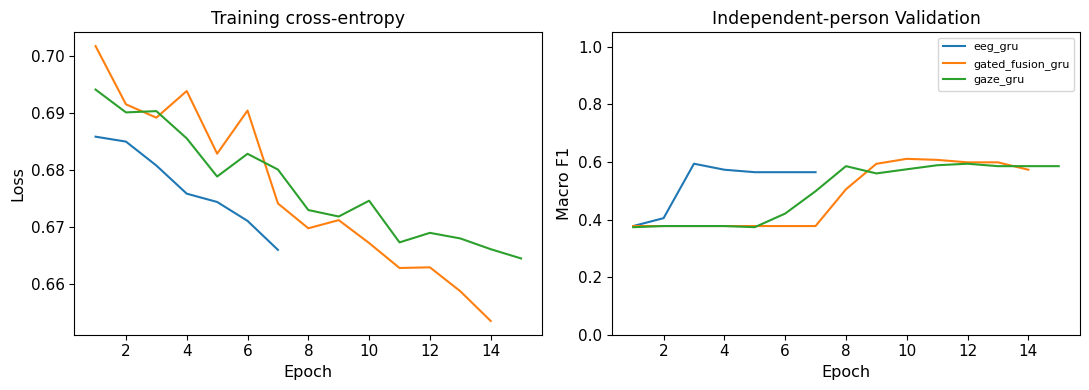

,model,partition,n_windows,n_people,parameters,best_epoch,accuracy,macro_f1,balanced_accuracy
2,gated_fusion_gru,validation,99,3,2354,10,0.646465,0.610718,0.609615
0,gaze_gru,validation,99,3,1090,12,0.626263,0.593767,0.592949
1,eeg_gru,validation,99,3,1090,3,0.626263,0.593767,0.592949


In [6]:
# ============= 05. Review Learning Curves and Validation Ranking =============

history = pd.DataFrame(histories)
neural_metrics = pd.DataFrame(validation_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, frame in history.groupby('model'):
    axes[0].plot(frame.epoch, frame.train_loss, label=name)
    axes[1].plot(frame.epoch, frame.macro_f1, label=name)
axes[0].set(title='Training cross-entropy', xlabel='Epoch',
            ylabel='Loss')
axes[1].set(title='Independent-person Validation',
            xlabel='Epoch', ylabel='Macro F1', ylim=(0, 1.05))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / '05_learning_curves.png', dpi=170)
plt.show()
display(neural_metrics.sort_values('macro_f1', ascending=False))


**06. Verify Validation Predictions and Save Temporal Evidence**

The executed Stage 05 generated and published **nine stage-owned outputs**:

| File or group | Recorded evidence |
| --- | --- |
| `05_validation_predictions.csv` | **297 rows**: three GRUs × **99 matching Validation window IDs**, with fixed NR/TSR targets and finite normalised class probabilities |
| `05_validation_metrics.csv` | Three pooled metric records, parameter counts, and selected epochs |
| `05_validation_person_metrics.csv` | **Nine rows**: three models × the three independently held-out participants, including task support and descriptive metrics |
| `05_training_history.csv` | **36 model/epoch rows**: 15 Gaze, seven EEG, 14 Gated |
| `05_scaling.npz` | Train-derived, modality-specific imputation and standardisation arrays |
| `05_gaze_gru.pt`, `05_eeg_gru.pt`, `05_gated_fusion_gru.pt` | Three selected GRU state dictionaries with architecture/epoch metadata |
| `05_learning_curves.png` | Train-loss and Validation-Macro-F1 trajectories |

**Independent reconciliation:** The **297 model/window pairs are unique**, each model covers all **99** matching source IDs (from `02_window_registry.csv` and Stage 04), and original participant/task labels are unchanged. Accuracy, Macro F1 and Balanced Accuracy recalculated from the saved predictions match all three summary rows. The per-person totals are **31** (`sub-YDR`), **38** (`sub-YRH`) and **30** (`sub-YTL`) windows **for each model**.

**Per-person Gated Fusion GRU Macro F1:** **0.3922** (`sub-YDR`), **0.6042** (`sub-YRH`) and **0.4000** (`sub-YTL`). This between-person spread matters because the pooled 99 windows do not represent 99 independent participants.

The saved files and Colab outputs support a successfully executed stage; the checks are not a second independent model-training run. **No final Test inference** is included.


In [7]:
# ============ 06. Verify and Save Stage-05 Validation Predictions ============

pred = pd.concat(prediction_frames, ignore_index=True)
expected_ids = set(table.iloc[idx_val].window_id)
if set(pred.model) != set(NEURAL_ORDER):
    raise ValueError('Missing or unexpected temporal candidate')
for name, piece in pred.groupby('model'):
    if (len(piece) != len(idx_val) or
            piece.window_id.duplicated().any() or
            set(piece.window_id) != expected_ids):
        raise ValueError(f'Validation identity mismatch: {name}')
    aligned = piece.set_index('window_id').loc[
        table.iloc[idx_val].window_id].reset_index()
    source = table.iloc[idx_val].reset_index(drop=True)
    for column in ('participant_id', 'task', 'split'):
        if not aligned[column].astype(str).eq(
                source[column].astype(str)).all():
            raise ValueError(f'Validation {column} mismatch: {name}')
    if not np.array_equal(
            aligned.target_index.to_numpy(),
            y[idx_val]):
        raise ValueError(f'Target index mismatch: {name}')
    values = aligned[['p_nr', 'p_tsr']].to_numpy(dtype=float)
    if (not np.isfinite(values).all() or
            (values < 0).any() or (values > 1).any() or
            not np.allclose(values.sum(axis=1), 1., atol=1e-5)):
        raise ValueError(f'Invalid Validation probabilities: {name}')
pred.to_csv(output_dir / '05_validation_predictions.csv',
            index=False)
neural_metrics.to_csv(output_dir / '05_validation_metrics.csv',
                      index=False)
history.to_csv(output_dir / '05_training_history.csv', index=False)
print('Neural Validation rows:', len(pred))

# Descriptive metrics for each independently held-out Validation person.
# Do not alter the frozen pooled-window Macro F1 selection criterion.
person_metrics = participant_prediction_metrics(pred)
person_support = person_metrics.groupby("model")["n_windows"].sum()
expected_person_rows = len(NEURAL_ORDER) * (
    table.iloc[idx_val].participant_id.nunique())
if (len(person_metrics) != expected_person_rows or
        not person_support.eq(len(idx_val)).all()):
    raise ValueError("Incomplete per-person temporal Validation evidence")
person_metrics.to_csv(
    output_dir / "05_validation_person_metrics.csv", index=False)
print("Per-person temporal Validation rows:", len(person_metrics))



Neural Validation rows: 297
Per-person temporal Validation rows: 9


**07. Interpretation and Next Dependency**

**Stage-05 conclusion:** All three compact temporal candidates were trained on the expanded **18-person source cohort**, using **371 Train windows**, evaluated on **99 Validation windows**, and saved together with checkpoints, scaling, history and per-person evidence. **Gated Fusion GRU** was the strongest temporal model with Macro F1 **0.6107**; each unimodal GRU scored **0.5938**.

**Comparison and uncertainty:** The current best classical candidate from Notebook 04, Gaze Random Forest, remains slightly above the strongest temporal GRU (**0.6244 versus 0.6107**) in pooled Validation Macro F1. However, three independent Validation people have heterogeneous results, and neither window-level ranking nor a small difference supports a population-level model superiority claim. The earlier six-person pilot's selected Gaze Logistic result **does not** determine the expanded study's outcome.

**Next stage:** [Notebook 06: Validation Selection and Robustness](06_robustness_and_final_evaluation.ipynb) will reconcile **seven classical and three temporal** predictions on the same **99 Validation windows**, apply the fixed Macro F1/then Balanced Accuracy/then candidate-priority selection rule, and conduct descriptive Validation-only feature masking of the unchanged early-fusion logistic model.

**Final Test boundary:** The **160 windows from four reserved Test participants** remain completely unscored. Notebook 06 must run with **`RUN_FINAL_TEST=False`** throughout the current development review. No performance, cognitive, clinical or causal interpretation is justified for Test or EEG–eye drift without separate evidence.


In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print('Next: 06_robustness_and_final_evaluation.ipynb')
download_outputs_from_colab("eeg_eye_tracking_fusion/output", "05")


Next: 06_robustness_and_final_evaluation.ipynb
------------------------------------------------------------------------
Notebook 05
Files packaged: 9
  + 05_eeg_gru.pt
  + 05_gated_fusion_gru.pt
  + 05_gaze_gru.pt
  + 05_learning_curves.png
  + 05_scaling.npz
  + 05_training_history.csv
  + 05_validation_metrics.csv
  + 05_validation_person_metrics.csv
  + 05_validation_predictions.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_05_Outputs.zip
